# **CI02 — Prévision de l’indice des quantités de blé importées au Maroc**
**Source : FAOSTAT, Trade Indices.** La cible est un **indice (2014–2016 = 100)**, et non un tonnage. Notebook Google Colab avec chemin Drive modifiable.

⚠️ Le guide de l’évaluation demande de rédiger le code d’analyse pendant la séance : respecter les instructions de votre enseignant et déclarer l’aide IA.

# **AHNNAOU YOUNESS, 23009126 , CI**

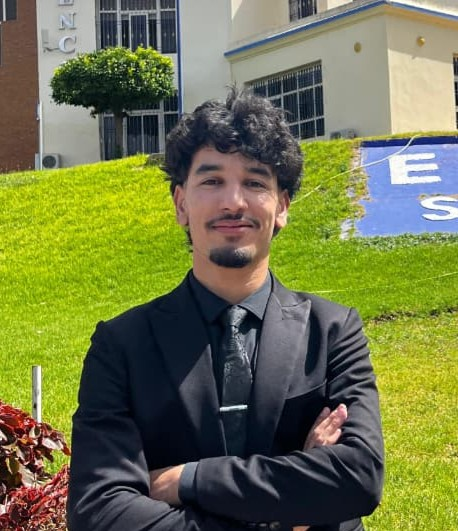**

In [3]:

# 1. Monter Google Drive (sur Colab uniquement)
from pathlib import Path
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Hors Google Colab : montage Drive ignoré.')

# MODIFIEZ ICI le chemin si votre fichier est déplacé :
DATA_PATH = '/content/drive/MyDrive/CC PARTIE B/FAOSTAT_data_en_11-19-2026.csv'
# Pour exécuter hors Colab, décommenter cette ligne et indiquer le fichier local :
# DATA_PATH = '/chemin/vers/FAOSTAT_data_en_11-19-2026.csv'
print('Fichier sélectionné :', DATA_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fichier sélectionné : /content/drive/MyDrive/CC PARTIE B/FAOSTAT_data_en_11-19-2026.csv


In [4]:
# 2. Importations et lecture
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
raw = pd.read_csv(DATA_PATH, low_memory=False)
print('Dimensions du CSV complet :', raw.shape)
display(raw.head())
print('Colonnes :', raw.columns.tolist())

Dimensions du CSV complet : (18240, 14)


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description
0,TI,Trade Indices,504,Morocco,462,Import Value Index (2014-2016 = 100),01929.06,"Agave fibres, raw, n.e.c.",2014,2014,NaN,100,E,Estimated value
1,TI,Trade Indices,504,Morocco,464,Import Unit/Value Index (2014-2016 = 100),01929.06,"Agave fibres, raw, n.e.c.",2014,2014,NaN,100,E,Estimated value
2,TI,Trade Indices,504,Morocco,465,Import Quantity Index (2014-2016 = 100),01929.06,"Agave fibres, raw, n.e.c.",2014,2014,NaN,100,E,Estimated value
3,TI,Trade Indices,504,Morocco,462,Import Value Index (2014-2016 = 100),01341,Apples,1961,1961,NaN,11,E,Estimated value
4,TI,Trade Indices,504,Morocco,462,Import Value Index (2014-2016 = 100),01341,Apples,1962,1962,NaN,7,E,Estimated value


Colonnes : ['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit', 'Value', 'Flag', 'Flag Description']


In [5]:
# 3. Filtrage exact : Maroc, blé, indice de quantité importée
selection = (raw['Area'].astype(str).str.strip().eq('Morocco') &
             raw['Item'].astype(str).str.strip().eq('Wheat') &
             raw['Element'].astype(str).str.strip().eq('Import Quantity Index (2014-2016 = 100)'))
df = raw.loc[selection, ['Year','Value','Area','Item','Element','Flag']].copy()
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df['Value'] = pd.to_numeric(df['Value'], errors='coerce')
print('Observations filtrées :',len(df))
print('Manquants :\n',df.isna().sum())
print('Années dupliquées :',df.duplicated(['Year']).sum())
assert len(df)>10, 'Pas assez de données : vérifier les libellés du CSV.'
assert df.duplicated(['Year']).sum()==0, 'Années dupliquées : vérifier la source.'
df = df.dropna(subset=['Year','Value']).sort_values('Year').reset_index(drop=True)
df['Year']=df['Year'].astype(int)
print('Période :',df.Year.min(),'-',df.Year.max())
display(df.head(8))
display(df[['Value']].describe())

Observations filtrées : 64
Manquants :
 Year       0
Value      0
Area       0
Item       0
Element    0
Flag       0
dtype: int64
Années dupliquées : 0
Période : 1961 - 2024


,Year,Value,Area,Item,Element,Flag
0,1961,8,Morocco,Wheat,Import Quantity Index (2014-2016 = 100),E
1,1962,7,Morocco,Wheat,Import Quantity Index (2014-2016 = 100),E
2,1963,2,Morocco,Wheat,Import Quantity Index (2014-2016 = 100),E
3,1964,4,Morocco,Wheat,Import Quantity Index (2014-2016 = 100),E
4,1965,5,Morocco,Wheat,Import Quantity Index (2014-2016 = 100),E
5,1966,12,Morocco,Wheat,Import Quantity Index (2014-2016 = 100),E
6,1967,17,Morocco,Wheat,Import Quantity Index (2014-2016 = 100),E
7,1968,12,Morocco,Wheat,Import Quantity Index (2014-2016 = 100),E


,Value
count,64.000000
mean,47.593750
std,32.407974
min,2.000000
25%,25.500000
50%,43.000000
75%,68.250000
max,129.000000


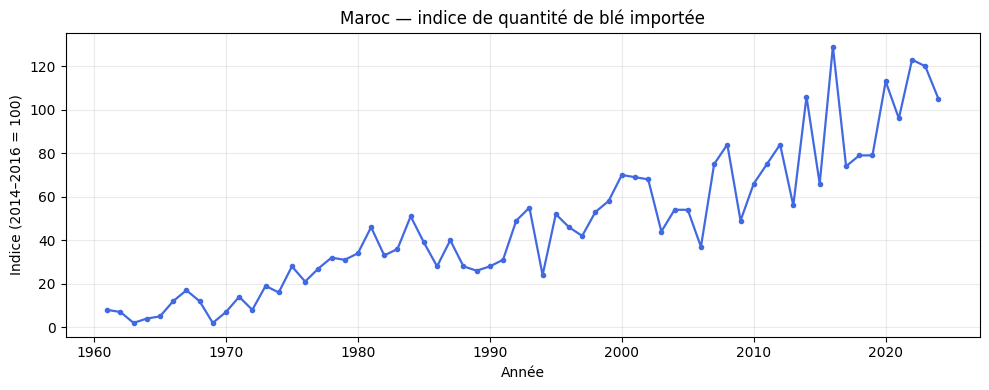

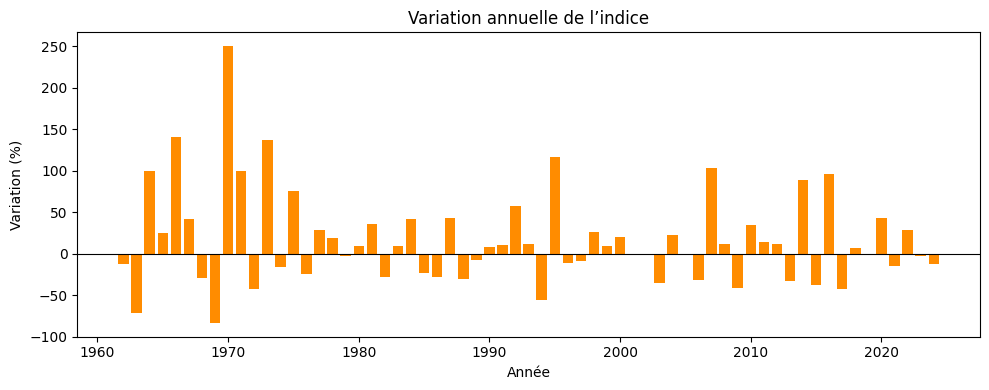

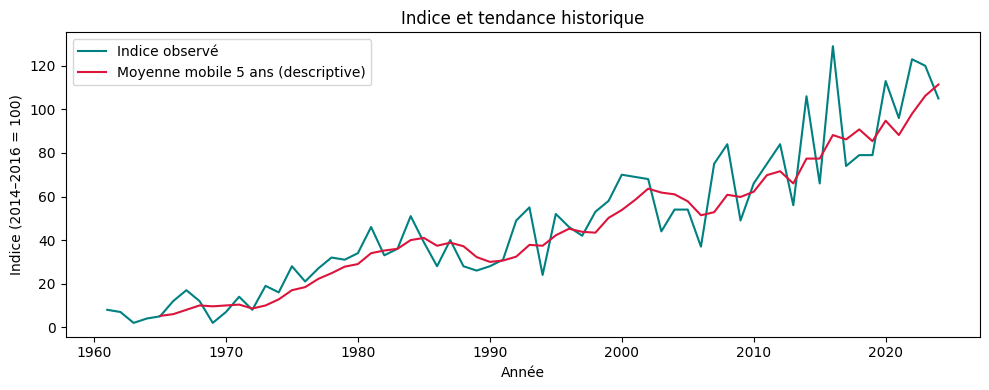

Graphiques enregistrés dans : /content/drive/MyDrive/CC PARTIE B/figures


In [6]:
# 4. Exploration : 3 figures enregistrées
from pathlib import Path
FIG_DIR = Path('/content/drive/MyDrive/CC PARTIE B/figures') if Path('/content/drive/MyDrive').exists() else Path('figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=170, bbox_inches='tight'); plt.show()

plt.figure(figsize=(10,4));plt.plot(df.Year,df.Value,color='royalblue',marker='.',linewidth=1.6)
plt.title('Maroc — indice de quantité de blé importée');plt.xlabel('Année');plt.ylabel('Indice (2014–2016 = 100)');plt.grid(alpha=.25);savefig('01_evolution.png')

df['variation_pct']=df.Value.pct_change(fill_method=None)*100
plt.figure(figsize=(10,4));plt.bar(df.Year,df.variation_pct,color='darkorange');plt.axhline(0,color='black',linewidth=.8)
plt.title('Variation annuelle de l’indice');plt.xlabel('Année');plt.ylabel('Variation (%)');savefig('02_variation.png')

plt.figure(figsize=(10,4));plt.plot(df.Year,df.Value,label='Indice observé',color='teal');plt.plot(df.Year,df.Value.rolling(5,min_periods=5).mean(),label='Moyenne mobile 5 ans (descriptive)',color='crimson')
plt.title('Indice et tendance historique');plt.xlabel('Année');plt.ylabel('Indice (2014–2016 = 100)');plt.legend();savefig('03_tendance.png')
print('Graphiques enregistrés dans :',FIG_DIR)

## Interprétation à rédiger
Observer les fluctuations, la tendance, les années extrêmes et le caractère volatil de la série. La moyenne mobile est **descriptive** : elle n’est pas utilisée comme variable future.

In [7]:
# 5. Variables retardées (seules les informations du passé sont utilisées)
s = df[['Year','Value']].copy()
s['lag1'] = s.Value.shift(1)
s['lag2'] = s.Value.shift(2)
s['lag3'] = s.Value.shift(3)
model_df=s.dropna().reset_index(drop=True)
FEATURES=['lag1','lag2','lag3']
# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test
n=len(model_df); end_train=int(n*.70);end_val=int(n*.85)
train=model_df.iloc[:end_train];valid=model_df.iloc[end_train:end_val];test=model_df.iloc[end_val:]
assert min(len(train),len(valid),len(test))>=3
print('Train :',train.Year.min(),train.Year.max(),len(train))
print('Validation :',valid.Year.min(),valid.Year.max(),len(valid))
print('Test :',test.Year.min(),test.Year.max(),len(test))

Train : 1964 2005 42
Validation : 2006 2014 9
Test : 2015 2024 10


In [8]:
# 6. Baseline naïve et choix de l'hyperparamètre Ridge sur validation
Xtr,ytr=train[FEATURES],train.Value
Xv,yv=valid[FEATURES],valid.Value
Xt,yt=test[FEATURES],test.Value
candidates=[0.1,1.0,10.0,100.0]
validation=[]
for alpha in candidates:
    model=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=alpha))])
    model.fit(Xtr,ytr)
    validation.append({'alpha':alpha,'MAE_validation':mean_absolute_error(yv,model.predict(Xv))})
val_table=pd.DataFrame(validation).sort_values('MAE_validation')
display(val_table)
best_alpha=float(val_table.iloc[0]['alpha'])
print('Alpha retenu sur validation :',best_alpha)

,alpha,MAE_validation
0,0.1,19.180535
1,1.0,19.210965
2,10.0,19.638348
3,100.0,23.240436


Alpha retenu sur validation : 0.1


,Modèle,MAE,RMSE,R²
1,Ridge,22.473,28.591,-0.751
2,Random Forest,23.650,29.644,-0.882
0,Naïf (année précédente),25.900,33.207,-1.362


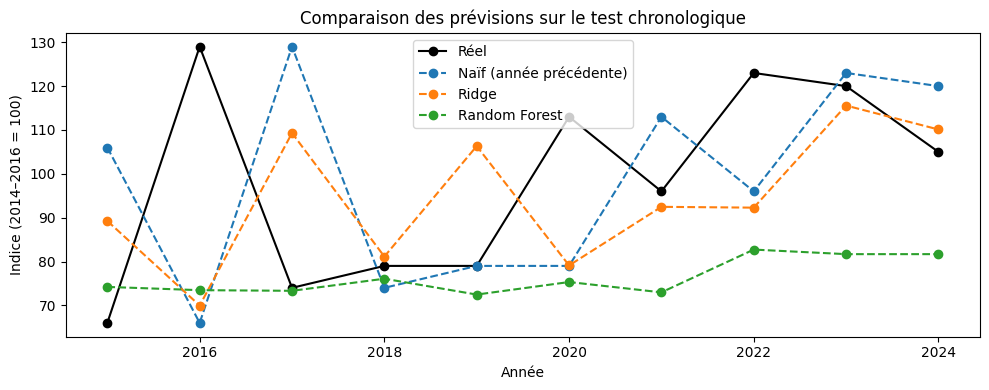

,Year,Réel,Naïf,Ridge,Random Forest,Erreur_absolue_Ridge
51,2015,66,106.0,89.25,74.21,23.25
52,2016,129,66.0,69.96,73.47,59.04
53,2017,74,129.0,109.30,73.32,35.30
54,2018,79,74.0,81.13,76.08,2.13
55,2019,79,79.0,106.32,72.46,27.32
56,2020,113,79.0,79.10,75.32,33.90
57,2021,96,113.0,92.47,72.97,3.53
58,2022,123,96.0,92.28,82.72,30.72
59,2023,120,123.0,115.57,81.68,4.43
60,2024,105,120.0,110.11,81.68,5.11


In [9]:
# 7. Ajustement final sur train+validation, test utilisé une seule fois
trainval=pd.concat([train,valid],ignore_index=True)
ridge=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=best_alpha))])
ridge.fit(trainval[FEATURES],trainval.Value)
forest=RandomForestRegressor(n_estimators=200,max_depth=4,random_state=SEED)
forest.fit(trainval[FEATURES],trainval.Value)
predictions={'Naïf (année précédente)':test['lag1'].to_numpy(),
             'Ridge':ridge.predict(Xt), 'Random Forest':forest.predict(Xt)}
results=[]
for name,pred in predictions.items():
    results.append({'Modèle':name,'MAE':mean_absolute_error(yt,pred),
                    'RMSE':np.sqrt(mean_squared_error(yt,pred)),
                    'R²':r2_score(yt,pred)})
metrics=pd.DataFrame(results).sort_values('MAE')
display(metrics.round(3))
plt.figure(figsize=(10,4));plt.plot(test.Year,yt,'o-',color='black',label='Réel')
for name,pred in predictions.items():plt.plot(test.Year,pred,'o--',label=name)
plt.title('Comparaison des prévisions sur le test chronologique');plt.xlabel('Année');plt.ylabel('Indice (2014–2016 = 100)');plt.legend();savefig('04_test_predictions.png')
errors=pd.DataFrame({'Year':test.Year,'Réel':yt,'Naïf':predictions['Naïf (année précédente)'],'Ridge':predictions['Ridge'],'Random Forest':predictions['Random Forest']})
errors['Erreur_absolue_Ridge']=(errors['Réel']-errors['Ridge']).abs()
display(errors.round(2))
metrics.to_csv(FIG_DIR/'comparaison_modeles.csv',index=False)
errors.to_csv(FIG_DIR/'predictions_test.csv',index=False)

In [10]:
# 8. Prévision exploratoire de l'année suivante (Ridge réentraîné sur toute l'histoire)
final_model=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=best_alpha))])
final_model.fit(model_df[FEATURES],model_df.Value)
next_year=int(df.Year.max()+1)
next_features=pd.DataFrame([{'lag1':df.Value.iloc[-1],'lag2':df.Value.iloc[-2],'lag3':df.Value.iloc[-3]}])
forecast=float(final_model.predict(next_features)[0])
print(f'Prévision indicative pour {next_year} : {forecast:.2f} points d’indice (2014–2016=100)')
print('ATTENTION : estimation incertaine, pas une quantité en tonnes.')

Prévision indicative pour 2025 : 120.26 points d’indice (2014–2016=100)
ATTENTION : estimation incertaine, pas une quantité en tonnes.


## Conclusion et limites
Comparer la MAE du meilleur modèle avec la référence naïve. Mentionner le faible nombre d’années, les chocs climatiques et commerciaux, l’absence de variables explicatives externes et le fait que la cible est un **indice**. Les performances hors échantillon ne prouvent pas une relation causale.

**Sources :** FAOSTAT, export fourni le 19/11/2026 ; consignes ENCG Settat, Partie B.